# Data-constrained medical image classification: global + local visual features + LLM text

Pipeline (COVID and BUSI): frozen ViT-B/16 baseline, small-kernel local branch (DKA-inspired), MedGemma per-image text (description + 10 answers), BioMedCLIP text embeddings, fusion head, ablations.

**Before you run**
1. Runtime > Change runtime type > GPU (T4 works for MedGemma 4B; L4 or A100 is faster).
2. Colab Secrets (key icon, left sidebar), notebook access ON: `HF_TOKEN`, `KAGGLE_USERNAME`, `KAGGLE_KEY`.
3. Accept the MedGemma license on its Hugging Face page (google/medgemma-4b-it).
4. Everything is cached to Google Drive (the setup cell asserts that Drive is mounted), so every stage is resumable after a disconnect: rerun cells top to bottom and finished work is skipped.

**Sections:** 0 Setup, 1 Data, 2 Splits, 3 Frozen ViT features, 4 MedGemma captions, 5 Leakage check, 6 Text embeddings, 7 Models and training, 8 Run all experiments, 9 Results, 10 Caption audit.

## 0. Setup

In [1]:
!pip install -q -U transformers accelerate bitsandbytes open_clip_torch timm kagglehub

In [2]:
import os, json, random, re, glob, gc, time, math, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score

from google.colab import drive, userdata
drive.mount('/content/drive')
assert os.path.ismount('/content/drive'), 'Drive is NOT mounted. Fix this before continuing (approve the Drive prompt, right account).'
import transformers; transformers.logging.set_verbosity_error()   # silences the repeated processor warning

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'

CFG = dict(
    WORK = '/content/drive/MyDrive/medvlm_fusion',
    SEEDS = [0],                           # independent class-balanced draws (add 1, 2 later if time allows)
    # fractions are relative to the TRAIN pool (the 80% left after the fixed 20% test split)
    FRACTIONS = {'busi': [0.0063, 0.0125, 0.125],
                 'covid': [0.0063]},           # lean settings (captioning is the slow step); add more later, saved captions are reused
    TEST_FRAC = 0.2,
    TEST_CAP = {'busi': None, 'covid': 150},   # cap the COVID test set (stratified); None = full 20%
    EPOCHS = 100, BATCH = 8,
    LR_NEW = 1e-3, LR_HEAD = 1e-4,             # asynchronous learning rates (DKA finding)
    HID = 128, P_DROP = 0.3, P_MOD = 0.2,
    VIT = 'vit_base_patch16_224',
    VLM_ID = 'google/medgemma-4b-it',          # or 'google/medgemma-1.5-4b-it'
    MAX_NEW_TOKENS = 300,
    SCRUB_LEAKS = True,                        # redact class names found in captions before embedding
)
WORK = Path(CFG['WORK']); WORK.mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(0)
print('device:', DEV, '| work dir:', WORK)

Mounted at /content/drive
device: cpu | work dir: /content/drive/MyDrive/medvlm_fusion


## 1. Data
Downloads both datasets from Kaggle (COVID-19 Radiography Database, 4 classes; BUSI, 3 classes, mask files excluded).
If you prefer your own copy, set `covid_root` / `busi_root` to the folders manually.

In [3]:
import kagglehub
for k in ['KAGGLE_USERNAME', 'KAGGLE_KEY', 'KAGGLE_API_TOKEN']:
    try:
        os.environ[k] = userdata.get(k)
    except Exception:
        pass   # secret not set, skip it
covid_root = Path(kagglehub.dataset_download('tawsifurrahman/covid19-radiography-database'))
busi_root  = Path(kagglehub.dataset_download('aryashah2k/breast-ultrasound-images-dataset'))
print(covid_root, busi_root)

100%|██████████| 778M/778M [00:13<00:00, 59.5MB/s]

Extracting files...


Using Colab cache for faster access to the 'breast-ultrasound-images-dataset' dataset.
/root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5 /kaggle/input/breast-ultrasound-images-dataset


In [4]:
def build_covid(root):
    rows = []
    for p in Path(root).rglob('*.png'):
        if p.parent.name != 'images':      # skip the lung masks
            continue
        rows.append((str(p), p.parent.parent.name))
    return rows

def build_busi(root):
    rows = []
    for p in Path(root).rglob('*.png'):
        if '_mask' in p.name:              # skip segmentation masks
            continue
        rows.append((str(p), p.parent.name))
    return rows

frames = []
for ds, rows in [('covid', build_covid(covid_root)), ('busi', build_busi(busi_root))]:
    d = pd.DataFrame(rows, columns=['path', 'cls'])
    d['ds'] = ds
    d['id'] = ds + '|' + d['cls'] + '|' + d['path'].map(lambda s: Path(s).name)
    classes = sorted(d['cls'].unique())
    d['y'] = d['cls'].map({c: i for i, c in enumerate(classes)})
    d = d.sort_values('id').reset_index(drop=True)      # fixed order => reproducible splits
    frames.append(d)
    print(ds, len(d), d['cls'].value_counts().to_dict())
DF = {d['ds'].iloc[0]: d for d in frames}
CLASSES = {ds: sorted(d['cls'].unique()) for ds, d in DF.items()}

covid 21165 {'Normal': 10192, 'Lung_Opacity': 6012, 'COVID': 3616, 'Viral Pneumonia': 1345}
busi 780 {'benign': 437, 'malignant': 210, 'normal': 133}


## 2. Splits
- Fixed stratified 20% test set per dataset (seed 0).
- Training subsets: class-proportional, at least 1 image per class, **nested** within a seed (0.63% is contained in 1.25%, and so on).
- The DKA paper uses 5-fold CV on the train subset. With 4 training images that is not possible, so this notebook uses **independent random draws (SEEDS)** of the subset and reports mean ± std over them. Say this in your writeup.

In [5]:
def make_splits(ds):
    d = DF[ds]
    tr, te = train_test_split(d.index.values, test_size=CFG['TEST_FRAC'], stratify=d['y'].values, random_state=0)
    cap = CFG['TEST_CAP'][ds]
    if cap and len(te) > cap:
        te, _ = train_test_split(te, train_size=cap, stratify=d['y'].values[te], random_state=0)
    return list(tr), list(te)

def subset(ds, pool, frac, seed):
    d = DF[ds]
    rng = np.random.RandomState(seed)
    out = []
    for c, g in d.loc[pool].groupby('y'):
        idx = g.index.values.copy()
        rng.shuffle(idx)                                   # same shuffle for every frac => nested subsets
        n = max(1, int(round(frac * len(idx))))
        out += list(idx[:n])
    return out

SPLITS = {}
for ds in DF:
    pool, te = make_splits(ds)
    SPLITS[ds] = {'pool': pool, 'test': te, 'train': {}}
    for seed in CFG['SEEDS']:
        for frac in CFG['FRACTIONS'][ds]:
            SPLITS[ds]['train'][(seed, frac)] = subset(ds, pool, frac, seed)
    needed = set(te)
    for v in SPLITS[ds]['train'].values(): needed |= set(v)
    SPLITS[ds]['needed'] = sorted(needed)
    print(ds, '| train pool', len(pool), '| test', len(te), '| images needing features/captions', len(needed))
    for frac in CFG['FRACTIONS'][ds]:
        s = SPLITS[ds]['train'][(CFG['SEEDS'][0], frac)]
        print('   frac', frac, '->', len(s), 'train images, per-class', DF[ds].loc[s, 'y'].value_counts().sort_index().tolist())

json.dump({ds: {'test': DF[ds].loc[S['test'], 'id'].tolist(),
                'train': {f'{k[0]}_{k[1]}': DF[ds].loc[v, 'id'].tolist() for k, v in S['train'].items()}}
           for ds, S in SPLITS.items()}, open(WORK / 'splits.json', 'w'))

covid | train pool 16932 | test 150 | images needing features/captions 256
   frac 0.0063 -> 106 train images, per-class [18, 30, 51, 7]
busi | train pool 624 | test 156 | images needing features/captions 234
   frac 0.0063 -> 4 train images, per-class [2, 1, 1]
   frac 0.0125 -> 7 train images, per-class [4, 2, 1]
   frac 0.125 -> 78 train images, per-class [44, 21, 13]


In [6]:
for d in ['covid']:
    DF.pop(d, None); SPLITS.pop(d, None); CLASSES.pop(d, None)

## 3. Frozen ViT-B/16 features (global CLS + patch tokens)
Cached in fp16 to Drive. Patch tokens are about 300 KB per image, so only the images the splits need are cached.

In [7]:
import timm
from timm.data import resolve_data_config, create_transform

vit = timm.create_model(CFG['VIT'], pretrained=True).to(DEV).eval()
for p in vit.parameters(): p.requires_grad = False
vit_dtype = torch.float16 if DEV == 'cuda' else torch.float32
vit = vit.to(vit_dtype)
tfm = create_transform(**resolve_data_config({}, model=vit))

@torch.no_grad()
def extract_feats(paths, bs=32):
    cls_l, pat_l = [], []
    for i in tqdm(range(0, len(paths), bs), desc='ViT'):
        x = torch.stack([tfm(Image.open(p).convert('RGB')) for p in paths[i:i+bs]]).to(DEV).to(vit_dtype)
        t = vit.forward_features(x)                       # B,197,768
        cls_l.append(t[:, 0].float().cpu().half()); pat_l.append(t[:, 1:].float().cpu().half())
    return torch.cat(cls_l), torch.cat(pat_l)

FEATS = {}
for ds in DF:
    f = WORK / f'feats_{ds}.pt'
    ids = DF[ds].loc[SPLITS[ds]['needed'], 'id'].tolist()
    if f.exists():
        FEATS[ds] = torch.load(f)
        if FEATS[ds]['ids'] == ids:
            print(ds, 'loaded cached features', FEATS[ds]['cls'].shape); continue
        print(ds, 'cached features do not match the current splits, recomputing')
    cls, pat = extract_feats(DF[ds].loc[SPLITS[ds]['needed'], 'path'].tolist())
    FEATS[ds] = {'ids': ids, 'cls': cls, 'patches': pat}
    torch.save(FEATS[ds], f)
    print(ds, 'saved', cls.shape, pat.shape)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

busi loaded cached features torch.Size([234, 768])


## 4. Per-image text from MedGemma
Each image gets one JSON with a `description` and 10 `answers` (the dataset-level questions below). The model is **not told the class**, and is told not to name a diagnosis. Decoding is greedy (`do_sample=False`, equivalent to temperature 0). Output goes to JSONL on Drive and the loop resumes where it stopped.

Edit the 10 questions if you want; keep exactly 10.

In [ ]:
QUESTIONS = {
 'covid': [
  "Describe any lung opacity: which zones (upper/middle/lower) and whether focal, patchy or diffuse.",
  "Are any abnormal densities unilateral or bilateral, symmetric or asymmetric?",
  "Describe the density and texture of the lung fields (clear, hazy ground-glass-like, dense consolidation-like, reticular).",
  "How much of the lung fields appear clear versus obscured?",
  "Describe the cardiac silhouette: size and clarity of its borders.",
  "Are the costophrenic angles sharp or blunted?",
  "Describe the diaphragm contours and whether they are clearly visible.",
  "Are there visible tubes, lines, electrodes or other devices?",
  "Describe the vascular markings and the hila.",
  "Comment on image quality: rotation, inspiration, exposure, artifacts.",
 ],
 'busi': [
  "Is a focal lesion visible? Describe where it sits in the image.",
  "What is the lesion shape: oval, round or irregular? (say 'no lesion visible' if none)",
  "Describe the lesion margins: circumscribed, indistinct, angular, microlobulated or spiculated.",
  "Describe the orientation: parallel to the skin (wider than tall) or not parallel.",
  "Describe the echo pattern: anechoic, hypoechoic, isoechoic, hyperechoic or heterogeneous.",
  "Describe the posterior acoustic features: enhancement, shadowing or none.",
  "Is the internal echotexture homogeneous or heterogeneous? Any bright foci?",
  "Describe the surrounding tissue: halo, architectural distortion, or unremarkable.",
  "Roughly how large is the lesion relative to the image, and how many lesions are visible?",
  "Comment on image quality: artifacts, calipers, text annotations, depth.",
 ]}
MODALITY = {'covid': 'frontal chest X-ray', 'busi': 'breast ultrasound image'}
assert all(len(v) == 10 for v in QUESTIONS.values())

PROMPT_TMPL = '''This is a <<MODALITY>>. Analyse only what is visible.
Return ONLY valid JSON (no markdown fences) with exactly this schema:
{"description": "<3-4 sentences describing the visible findings>", "answers": ["<answer to Q1>", "<answer to Q2>", "<answer to Q3>", "<answer to Q4>", "<answer to Q5>", "<answer to Q6>", "<answer to Q7>", "<answer to Q8>", "<answer to Q9>", "<answer to Q10>"]}
Rules: each answer is ONE short sentence. Do NOT state or hint at a diagnosis, disease name or class label; describe appearance only. If a feature is not visible, say so.
Questions:
<<QUESTIONS>>'''
def build_prompt(ds):
    q = "\n".join(f"{i+1}. {t}" for i, t in enumerate(QUESTIONS[ds]))
    return PROMPT_TMPL.replace('<<MODALITY>>', MODALITY[ds]).replace('<<QUESTIONS>>', q)
print(build_prompt('busi'))

This is a breast ultrasound image. Analyse only what is visible.
Return ONLY valid JSON (no markdown fences) with exactly this schema:
{"description": "<3-4 sentences describing the visible findings>", "answers": ["<answer to Q1>", "<answer to Q2>", "<answer to Q3>", "<answer to Q4>", "<answer to Q5>", "<answer to Q6>", "<answer to Q7>", "<answer to Q8>", "<answer to Q9>", "<answer to Q10>"]}
Rules: each answer is ONE short sentence. Do NOT state or hint at a diagnosis, disease name or class label; describe appearance only. If a feature is not visible, say so.
Questions:
1. Is a focal lesion visible? Describe where it sits in the image.
2. What is the lesion shape: oval, round or irregular? (say 'no lesion visible' if none)
3. Describe the lesion margins: circumscribed, indistinct, angular, microlobulated or spiculated.
4. Describe the orientation: parallel to the skin (wider than tall) or not parallel.
5. Describe the echo pattern: anechoic, hypoechoic, isoechoic, hyperechoic or heter

In [ ]:
from huggingface_hub import login, model_info
from transformers import AutoProcessor, AutoModelForImageTextToText
login(userdata.get('HF_TOKEN'))

vlm_dtype = torch.bfloat16            # if outputs are garbage/NaN on a T4, load with load_in_4bit instead (see note below)
vlm = AutoModelForImageTextToText.from_pretrained(CFG['VLM_ID'], torch_dtype=vlm_dtype, device_map='auto')
proc = AutoProcessor.from_pretrained(CFG['VLM_ID'])
proc.tokenizer.padding_side = 'left'
try: sha = model_info(CFG['VLM_ID']).sha
except Exception: sha = 'unknown'
json.dump({'model': CFG['VLM_ID'], 'commit': sha, 'dtype': str(vlm_dtype), 'greedy': True,
           'max_new_tokens': CFG['MAX_NEW_TOKENS'], 'prompts': {k: build_prompt(k) for k in QUESTIONS}},
          open(WORK / 'vlm_meta.json', 'w'), indent=1)
print('loaded', CFG['VLM_ID'], sha)
# 4-bit alternative:  from transformers import BitsAndBytesConfig
# vlm = AutoModelForImageTextToText.from_pretrained(ID, device_map='auto', quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16))

config.json:   0%|          | 0.00/2.47k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

loaded google/medgemma-4b-it 290cda5eeccbee130f987c4ad74a59ae6f196408


In [ ]:
def vlm_ask(img, prompt):
    messages = [
        {"role": "system", "content": [{"type": "text", "text": "You are an expert radiologist."}]},
        {"role": "user", "content": [{"type": "text", "text": prompt}, {"type": "image", "image": img}]},
    ]
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True,
                                      return_dict=True, return_tensors='pt').to(vlm.device, dtype=vlm_dtype)
    n = inputs['input_ids'].shape[-1]
    with torch.inference_mode():
        out = vlm.generate(**inputs, max_new_tokens=CFG['MAX_NEW_TOKENS'], do_sample=False)
    return proc.decode(out[0][n:], skip_special_tokens=True)

def parse_json(raw):
    m = re.search(r'\{.*\}', raw, re.S)
    if not m: return None
    try: obj = json.loads(m.group(0))
    except json.JSONDecodeError: return None
    if not isinstance(obj, dict) or not isinstance(obj.get('description'), str): return None
    ans = obj.get('answers')
    if not isinstance(ans, list): return None
    ans = [str(a) for a in ans][:10]
    ans += [''] * (10 - len(ans))
    return {'description': obj['description'], 'answers': ans}

def vlm_ask_batch(imgs, prompt):
    convs = [[
        {"role": "system", "content": [{"type": "text", "text": "You are an expert radiologist."}]},
        {"role": "user", "content": [{"type": "text", "text": prompt}, {"type": "image", "image": im}]},
    ] for im in imgs]
    inputs = proc.apply_chat_template(convs, add_generation_prompt=True, tokenize=True,
                                      return_dict=True, return_tensors='pt', padding=True
                                      ).to(vlm.device, dtype=vlm_dtype)
    n = inputs['input_ids'].shape[-1]
    with torch.inference_mode():
        out = vlm.generate(**inputs, max_new_tokens=CFG['MAX_NEW_TOKENS'], do_sample=False)
    return [proc.decode(o[n:], skip_special_tokens=True) for o in out]

def ask_safe(imgs, prompt):
    try:
        return vlm_ask_batch(imgs, prompt)
    except torch.cuda.OutOfMemoryError:
        gc.collect(); torch.cuda.empty_cache()
        if len(imgs) == 1:
            raise
        h = len(imgs) // 2
        return ask_safe(imgs[:h], prompt) + ask_safe(imgs[h:], prompt)

def caption_dataset(ds, bs=4):
    out = WORK / f'captions_{ds}.jsonl'
    done = {json.loads(l)['id'] for l in open(out)} if out.exists() else set()
    todo = [(r.id, r.path) for r in DF[ds].loc[SPLITS[ds]['needed']].itertuples() if r.id not in done]
    print(ds, 'to caption:', len(todo), '| already done:', len(done))
    prompt = build_prompt(ds)
    with open(out, 'a') as f:
        for i in tqdm(range(0, len(todo), bs), desc=f'caption {ds}'):
            chunk = todo[i:i + bs]
            raws = ask_safe([Image.open(p).convert('RGB') for _, p in chunk], prompt)
            for (iid, _), raw in zip(chunk, raws):
                f.write(json.dumps({'id': iid, 'raw': raw, 'parsed': parse_json(raw)}) + '\n')
            f.flush()

# Smoke test on 3 images first:
for r in DF['busi'].loc[SPLITS['busi']['needed'][:3]].itertuples():
    raw = vlm_ask(Image.open(r.path).convert('RGB'), build_prompt('busi'))
    print(r.cls, '->', parse_json(raw) or raw[:300], '\n')

benign -> {'description': 'A focal lesion is visible in the upper outer quadrant of the breast. The lesion appears to be oval in shape with indistinct margins. The lesion has a heterogeneous echo pattern and no posterior acoustic enhancement or shadowing is seen. The internal echotexture is heterogeneous with bright foci present.', 'answers': ['Yes, a focal lesion is visible in the upper outer quadrant.', 'The lesion is oval.', 'The lesion margins are indistinct.', 'The lesion orientation is not parallel to the skin.', 'The lesion has a heterogeneous echo pattern.', 'No posterior acoustic enhancement is seen.', 'The internal echotexture is heterogeneous.', 'Bright foci are present within the lesion.', 'The lesion appears to be approximately 1.5 cm in size.', 'The image quality is adequate, with no obvious artifacts.']} 

benign -> {'description': 'A focal lesion is visible in the upper outer quadrant of the breast. The lesion appears to be oval in shape with indistinct margins. The les

In [ ]:
# BUSI first (resumable: rerun this cell after any disconnect and it continues).
# After it starts, check drive.google.com > My Drive > medvlm_fusion for captions_busi.jsonl.
caption_dataset('busi')

busi to caption: 234 | already done: 0


caption busi:   0%|          | 0/59 [00:00<?, ?it/s]

In [ ]:
# COVID next (separate cell so you can run it later)
caption_dataset('covid')

covid to caption: 256 | already done: 0


caption covid:   0%|          | 0/64 [00:00<?, ?it/s]

In [ ]:
# Free GPU memory for the next stages
del vlm, proc
gc.collect(); torch.cuda.empty_cache()

## 5. Leakage check and caption quality
Greps captions for class names. `normal` is excluded because it is a legitimate descriptive word. Anything found here is redacted before embedding when `SCRUB_LEAKS=True`. If the leak rate is high, fix the prompt and re-caption.

In [8]:
LEAK = {'covid': ['covid', 'coronavirus', 'pneumonia', 'viral'],
        'busi':  ['malignan', 'benign', 'cancer', 'carcinoma', 'tumor', 'tumour']}

def load_caps(ds):
    return {j['id']: j for j in map(json.loads, open(WORK / f'captions_{ds}.jsonl'))}

def all_text(rec):
    if rec['parsed']: return rec['parsed']['description'] + ' ' + ' '.join(rec['parsed']['answers'])
    return rec['raw']

for ds in DF:
    caps = load_caps(ds)
    n = len(caps); bad = sum(1 for c in caps.values() if c['parsed'] is None)
    print(f'== {ds}: {n} captions | JSON parse failures: {bad} ({bad/max(n,1):.1%})')
    for term in LEAK[ds]:
        hits = [i for i, c in caps.items() if term in all_text(c).lower()]
        print(f'   "{term}": {len(hits)} captions ({len(hits)/max(n,1):.1%})')
        for i in hits[:2]:
            t = all_text(caps[i]); k = t.lower().find(term)
            print('      e.g.', i.split('|')[1], '...', t[max(0, k-60):k+60].replace('\n', ' '))
    # does leaking correlate with the true class? (a leak that tracks the label is the dangerous kind)
    lab = DF[ds].set_index('id')['cls']
    rows = []
    for i, c in caps.items():
        t = all_text(c).lower()
        rows.append((lab[i], any(x in t for x in LEAK[ds])))
    print(pd.DataFrame(rows, columns=['cls', 'leak']).groupby('cls')['leak'].mean().round(3).to_dict())

== busi: 234 captions | JSON parse failures: 0 (0.0%)
   "malignan": 0 captions (0.0%)
   "benign": 0 captions (0.0%)
   "cancer": 0 captions (0.0%)
   "carcinoma": 0 captions (0.0%)
   "tumor": 0 captions (0.0%)
   "tumour": 0 captions (0.0%)
{'benign': 0.0, 'malignant': 0.0, 'normal': 0.0}


## 6. Text embeddings (BioMedCLIP text encoder, 512-d)
`td` = description embedding. `tq` = mean of the 10 answer embeddings. Failed JSON falls back to embedding the raw text as the description (answers zero).

In [9]:
import open_clip
BM = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
bm, _ = open_clip.create_model_from_pretrained(BM)
bm_tok = open_clip.get_tokenizer(BM)
bm = bm.to(DEV).eval()

@torch.no_grad()
def embed_texts(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        t = bm_tok(texts[i:i+bs], context_length=256).to(DEV)
        out.append(F.normalize(bm.encode_text(t).float(), dim=-1).cpu())
    return torch.cat(out) if out else torch.zeros(0, 512)

def scrub(text, ds):
    if not CFG['SCRUB_LEAKS']: return text
    return re.sub('|'.join(LEAK[ds]), '[redacted]', text, flags=re.I)

TEXT = {}
for ds in DF:
    f = WORK / f'texts_{ds}.pt'
    ids = FEATS[ds]['ids']
    if f.exists():
        TEXT[ds] = torch.load(f)
        if TEXT[ds]['ids'] == ids and TEXT[ds]['scrub'] == CFG['SCRUB_LEAKS']:
            print(ds, 'loaded cached text embeddings'); continue
    caps = load_caps(ds)
    missing = [i for i in ids if i not in caps]
    assert not missing, f'{len(missing)} images have no caption yet, e.g. {missing[:2]}'
    desc, ans, has_ans = [], [], []
    for i in ids:
        c = caps[i]
        if c['parsed']:
            desc.append(scrub(c['parsed']['description'], ds)); ans.append([scrub(a, ds) for a in c['parsed']['answers']]); has_ans.append(True)
        else:
            desc.append(scrub(c['raw'][:1500], ds)); ans.append([''] * 10); has_ans.append(False)
    td = embed_texts(desc)
    flat = [a if a else '.' for row in ans for a in row]
    tq_all = embed_texts(flat).view(len(ids), 10, -1)
    mask = torch.tensor(has_ans).float().view(-1, 1, 1)
    tq = (tq_all * mask).mean(1)
    TEXT[ds] = {'ids': ids, 'td': td, 'tq': tq, 'tq_all': tq_all * mask, 'scrub': CFG['SCRUB_LEAKS']}
    torch.save(TEXT[ds], f)
    print(ds, 'embedded', td.shape, tq.shape)
del bm; gc.collect(); torch.cuda.empty_cache()

open_clip_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  784MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/225k [00:00<?, ?B/s]

busi loaded cached text embeddings


## 7. Models and training
- **Baseline:** linear head on the frozen CLS token.
- **Local branch:** linear bottleneck (768 to 16), reshape patches to 14x14, 5x5 depthwise conv, GELU, global pool, linear to 128. This is a small-kernel head-side branch **inspired by** DKA (the real DKA sits inside the transformer blocks).
- **Fusion:** each stream is projected to 128-d (LayerNorm first), modality dropout, concatenate, MLP head.
- **Learning rates:** `LR_NEW` for the branches and projections, `LR_HEAD` for the classifier head (DKA's asynchronous-LR finding).
- No test-set model selection: the model after the last epoch is evaluated.

In [10]:
class LocalBranch(nn.Module):
    def __init__(self, d=768, mid=16, out=128, k=5):
        super().__init__()
        self.down = nn.Linear(d, mid)
        self.dw = nn.Conv2d(mid, mid, k, padding=k // 2, groups=mid)
        self.act = nn.GELU()
        self.out = nn.Linear(mid, out)
    def forward(self, p):                          # B,196,768
        x = self.down(p).transpose(1, 2).reshape(p.size(0), -1, 14, 14)
        return self.out(self.act(self.dw(x)).mean((2, 3)))

class Net(nn.Module):
    def __init__(self, n_cls, mods, linear=False, h=128, p_drop=0.3, p_mod=0.2):
        super().__init__()
        self.mods, self.linear, self.p_mod = tuple(mods), linear, p_mod
        if linear:
            self.head = nn.Linear(768, n_cls); self.branches = nn.ModuleDict()
            return
        b = {}
        if 'g' in mods:  b['g'] = nn.Sequential(nn.LayerNorm(768), nn.Linear(768, h))
        if 'l' in mods:  b['l'] = LocalBranch(out=h)
        if 'td' in mods: b['td'] = nn.Sequential(nn.LayerNorm(512), nn.Linear(512, h))
        if 'tq' in mods: b['tq'] = nn.Sequential(nn.LayerNorm(512), nn.Linear(512, h))
        self.branches = nn.ModuleDict(b)
        self.head = nn.Sequential(nn.Dropout(p_drop), nn.Linear(len(mods) * h, h), nn.GELU(), nn.Linear(h, n_cls))
    def forward(self, cls, pat, td, tq):
        if self.linear: return self.head(cls)
        src = {'g': cls, 'l': pat, 'td': td, 'tq': tq}
        z = [self.branches[m](src[m]) for m in self.mods]
        if self.training and len(z) > 1:           # modality dropout
            z = [m * (torch.rand(m.size(0), 1, device=m.device) > self.p_mod).float() for m in z]
        return self.head(torch.cat(z, -1))

VARIANTS = {
    'baseline':       dict(mods=('g',), linear=True),
    '+local':         dict(mods=('g', 'l')),
    '+desc':          dict(mods=('g', 'l', 'td')),
    '+answers':       dict(mods=('g', 'l', 'tq')),
    'full':           dict(mods=('g', 'l', 'td', 'tq')),
    'text_only':      dict(mods=('td', 'tq')),
    'full_shuf_test': dict(mods=('g', 'l', 'td', 'tq'), shuffle='test'),   # trained on real text, tested on another image's text
    'full_shuf_both': dict(mods=('g', 'l', 'td', 'tq'), shuffle='both'),   # text pairing broken in train and test
}

def derange(idx, g):
    n = len(idx)
    if n < 2: return idx
    p = torch.randperm(n, generator=g)
    m = torch.empty(n, dtype=torch.long); m[p] = p.roll(-1)
    return idx[m.to(idx.device)]

def load_ds(ds):
    pos = {i: k for k, i in enumerate(FEATS[ds]['ids'])}
    assert FEATS[ds]['ids'] == TEXT[ds]['ids']
    y = torch.tensor(DF[ds].set_index('id').loc[FEATS[ds]['ids'], 'y'].values)
    return dict(pos=pos, cls=FEATS[ds]['cls'].to(DEV), pat=FEATS[ds]['patches'].to(DEV),
                td=TEXT[ds]['td'].to(DEV), tq=TEXT[ds]['tq'].to(DEV), y=y.to(DEV), n_cls=len(CLASSES[ds]))

def run_one(D, tr, te, variant, seed):
    spec = VARIANTS[variant]
    set_seed(seed)
    net = Net(D['n_cls'], spec['mods'], spec.get('linear', False), CFG['HID'], CFG['P_DROP'], CFG['P_MOD']).to(DEV)
    if spec.get('linear'):
        opt = torch.optim.Adam(net.parameters(), lr=CFG['LR_NEW'])
    else:
        opt = torch.optim.Adam([{'params': net.branches.parameters(), 'lr': CFG['LR_NEW']},
                                {'params': net.head.parameters(), 'lr': CFG['LR_HEAD']}])
    g = torch.Generator().manual_seed(seed + 1234)
    tr = torch.tensor(tr, device=DEV); te = torch.tensor(te, device=DEV)
    txt_tr = derange(tr, g) if spec.get('shuffle') == 'both' else tr
    txt_te = derange(te, g) if spec.get('shuffle') in ('test', 'both') else te
    n = len(tr)
    for ep in range(CFG['EPOCHS']):
        net.train()
        perm = torch.randperm(n, device=DEV)
        for i in range(0, n, CFG['BATCH']):
            b = perm[i:i + CFG['BATCH']]
            logits = net(D['cls'][tr[b]].float(), D['pat'][tr[b]].float(), D['td'][txt_tr[b]], D['tq'][txt_tr[b]])
            loss = F.cross_entropy(logits, D['y'][tr[b]])
            opt.zero_grad(); loss.backward(); opt.step()
    net.eval(); preds = []
    with torch.no_grad():
        for i in range(0, len(te), 256):
            s = slice(i, i + 256)
            preds.append(net(D['cls'][te[s]].float(), D['pat'][te[s]].float(), D['td'][txt_te[s]], D['tq'][txt_te[s]]).argmax(-1).cpu())
    p = torch.cat(preds).numpy(); t = D['y'][te].cpu().numpy()
    return dict(acc=accuracy_score(t, p) * 100, f1=f1_score(t, p, average='macro', zero_division=0),
                sen=recall_score(t, p, average='macro', zero_division=0) * 100)   # SEN = macro-averaged recall

In [12]:
RES = WORK / 'results.csv'

In [13]:
ds = 'busi'
D = load_ds(ds)
d = DF[ds]
te = [D['pos'][i] for i in d.loc[SPLITS[ds]['test'], 'id']]
yt = D['y'].cpu().numpy()[te]
print('majority-class accuracy: %.1f%%' % (np.bincount(yt).max() / len(yt) * 100))

cap_pool = SPLITS[ds]['train'][(0, 0.125)]            # the 78 captioned training images
cls_n = d.loc[SPLITS[ds]['pool']].groupby('y').size()
def draw(frac, seed):
    rng = np.random.RandomState(100 + seed); out = []
    for c, g in d.loc[cap_pool].groupby('y'):
        idx = g.index.values.copy(); rng.shuffle(idx)
        out += list(idx[:max(1, int(round(frac * cls_n[c])))])
    return out

res = pd.read_csv(RES)
done = set(zip(res.ds, res.frac, res.variant, res.seed))
for frac in CFG['FRACTIONS'][ds]:
    for seed in [1, 2, 3, 4]:
        tr = [D['pos'][i] for i in d.loc[draw(frac, seed), 'id']]
        for v in ['baseline', '+local', '+desc', '+answers', 'full', 'text_only', 'full_shuf_test', 'full_shuf_both']:
            if (ds, frac, v, seed) in done: continue
            m = run_one(D, tr, te, v, seed)
            res.loc[len(res)] = dict(ds=ds, frac=frac, variant=v, seed=seed, n_train=len(tr), **m)
            res.to_csv(RES, index=False)
        print('done', frac, 'seed', seed)

majority-class accuracy: 55.8%
done 0.0063 seed 1
done 0.0063 seed 2
done 0.0063 seed 3
done 0.0063 seed 4
done 0.0125 seed 1
done 0.0125 seed 2
done 0.0125 seed 3
done 0.0125 seed 4
done 0.125 seed 1
done 0.125 seed 2
done 0.125 seed 3
done 0.125 seed 4


In [14]:
VARIANTS.update({'baseline_long': VARIANTS['baseline'], '+local_long': VARIANTS['+local'], 'full_long': VARIANTS['full']})
old = (CFG['EPOCHS'], CFG['LR_HEAD'])
CFG['EPOCHS'], CFG['LR_HEAD'] = 300, 1e-3
res = pd.read_csv(RES); done = set(zip(res.ds, res.frac, res.variant, res.seed))
for frac in CFG['FRACTIONS']['busi']:
    for seed in [0, 1, 2, 3, 4]:
        sub = SPLITS['busi']['train'][(0, frac)] if seed == 0 else draw(frac, seed)
        tr = [D['pos'][i] for i in d.loc[sub, 'id']]
        for v in ['baseline_long', '+local_long', 'full_long']:
            if ('busi', frac, v, seed) in done: continue
            m = run_one(D, tr, te, v, seed)
            res.loc[len(res)] = dict(ds='busi', frac=frac, variant=v, seed=seed, n_train=len(tr), **m)
            res.to_csv(RES, index=False)
CFG['EPOCHS'], CFG['LR_HEAD'] = old
print('done')

done


## 8. Run all experiments
Features and text are cached, so each run is a few seconds to a minute. Results append to `results.csv` on Drive and finished runs are skipped on restart.

In [ ]:
RES = WORK / 'results.csv'
res = pd.read_csv(RES) if RES.exists() else pd.DataFrame(columns=['ds', 'frac', 'variant', 'seed', 'acc', 'f1', 'sen', 'n_train'])
done = set(zip(res.ds, res.frac, res.variant, res.seed))

for ds in DF:
    D = load_ds(ds)
    te = [D['pos'][i] for i in DF[ds].loc[SPLITS[ds]['test'], 'id']]
    for frac in CFG['FRACTIONS'][ds]:
        for seed in CFG['SEEDS']:
            tr = [D['pos'][i] for i in DF[ds].loc[SPLITS[ds]['train'][(seed, frac)], 'id']]
            for v in VARIANTS:
                if (ds, frac, v, seed) in done: continue
                t0 = time.time()
                m = run_one(D, tr, te, v, seed)
                res.loc[len(res)] = dict(ds=ds, frac=frac, variant=v, seed=seed, n_train=len(tr), **m)
                res.to_csv(RES, index=False)
                print(f'{ds} {frac:<7} seed{seed} {v:<15} acc {m["acc"]:.2f} f1 {m["f1"]:.3f} sen {m["sen"]:.2f}  ({time.time()-t0:.0f}s)')
    del D; torch.cuda.empty_cache()

## 9. Results

In [15]:
res = pd.read_csv(RES)
def ms(x): return f'{x.mean():.2f} ± {x.std(ddof=0):.2f}'
order = list(VARIANTS)
for ds in DF:
    print(f'\n===== {ds.upper()} =====')
    for metric in ['acc', 'f1', 'sen']:
        t = (res[res.ds == ds].groupby(['variant', 'frac'])[metric].apply(ms).unstack('frac').reindex(order))
        print(f'\n[{metric}]'); display(t)
res.groupby(['ds', 'frac', 'variant'])[['acc', 'f1', 'sen']].agg(['mean', 'std']).round(3).to_csv(WORK / 'summary.csv')


===== BUSI =====

[acc]


frac,0.0063,0.0125,0.1250
variant,,,
baseline,50.90 ± 7.23,53.59 ± 4.09,66.41 ± 0.87
+local,52.18 ± 4.49,54.10 ± 4.49,68.08 ± 2.54
+desc,50.77 ± 7.25,54.23 ± 3.73,68.97 ± 0.87
+answers,50.64 ± 5.65,54.49 ± 4.19,67.69 ± 1.55
full,50.13 ± 8.02,54.62 ± 2.88,67.18 ± 2.12
text_only,39.49 ± 6.83,44.10 ± 9.28,51.67 ± 3.45
full_shuf_test,49.74 ± 8.38,54.74 ± 4.11,66.92 ± 1.44
full_shuf_both,51.15 ± 5.55,55.00 ± 1.92,66.79 ± 1.03
baseline_long,50.64 ± 7.00,53.85 ± 4.48,66.28 ± 0.51



[f1]


frac,0.0063,0.0125,0.1250
variant,,,
baseline,0.41 ± 0.07,0.34 ± 0.04,0.63 ± 0.01
+local,0.40 ± 0.05,0.34 ± 0.03,0.64 ± 0.03
+desc,0.39 ± 0.06,0.32 ± 0.02,0.64 ± 0.01
+answers,0.39 ± 0.06,0.34 ± 0.03,0.63 ± 0.02
full,0.36 ± 0.08,0.36 ± 0.05,0.63 ± 0.02
text_only,0.31 ± 0.05,0.31 ± 0.04,0.40 ± 0.02
full_shuf_test,0.36 ± 0.07,0.35 ± 0.07,0.63 ± 0.01
full_shuf_both,0.38 ± 0.06,0.34 ± 0.04,0.63 ± 0.01
baseline_long,0.40 ± 0.06,0.35 ± 0.05,0.63 ± 0.01



[sen]


frac,0.0063,0.0125,0.1250
variant,,,
baseline,42.69 ± 3.26,37.63 ± 2.75,62.58 ± 1.29
+local,41.23 ± 4.37,36.95 ± 3.25,64.27 ± 2.24
+desc,41.10 ± 3.84,35.96 ± 2.21,64.03 ± 1.64
+answers,41.03 ± 3.76,37.34 ± 2.71,63.59 ± 2.67
full,40.29 ± 4.69,38.42 ± 4.14,63.77 ± 1.92
text_only,33.35 ± 4.74,34.02 ± 5.03,40.80 ± 1.55
full_shuf_test,39.89 ± 4.19,38.32 ± 5.46,63.46 ± 1.24
full_shuf_both,40.95 ± 3.23,37.89 ± 3.39,64.06 ± 1.63
baseline_long,42.54 ± 3.50,38.03 ± 3.26,62.50 ± 0.73


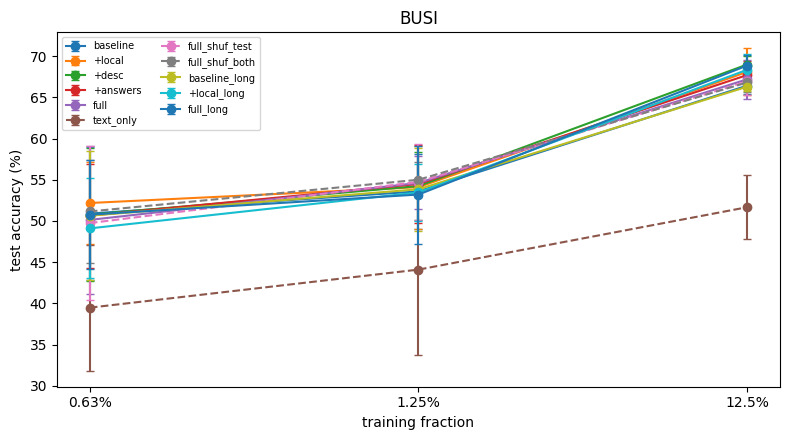

In [16]:
import matplotlib.pyplot as plt
for ds in DF:
    fr = CFG['FRACTIONS'][ds]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for v in order:
        s = res[(res.ds == ds) & (res.variant == v)].groupby('frac')['acc'].agg(['mean', 'std']).reindex(fr)
        ax.errorbar(range(len(fr)), s['mean'], yerr=s['std'].fillna(0), marker='o', capsize=3, label=v,
                    linestyle='--' if 'shuf' in v or v == 'text_only' else '-')
    ax.set_xticks(range(len(fr))); ax.set_xticklabels([f'{f*100:g}%' for f in fr])
    ax.set_xlabel('training fraction'); ax.set_ylabel('test accuracy (%)'); ax.set_title(ds.upper()); ax.legend(fontsize=7, ncol=2)
    plt.tight_layout(); plt.savefig(WORK / f'acc_{ds}.png', dpi=150); plt.show()

How to read the table:
- `baseline` vs `+local`: what the small-kernel branch adds on its own.
- `+desc`, `+answers`, `full` vs `+local`: what text adds.
- `text_only`: how much of the result is text alone.
- `full_shuf_test`: if accuracy falls toward `+local`, the model really uses image-grounded text. `full_shuf_both` shows the same idea with the pairing broken during training too.

## 10. Caption audit (about 50 images)
Shows 25 random captions per dataset with the image. Rate each in the CSV (`faithful`: 1 if the description matches the image, 0 if it hallucinates or is vague; `notes`). Report the rates in your limitations.

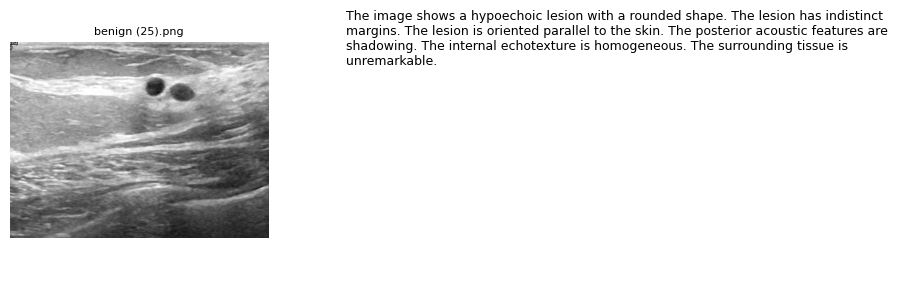

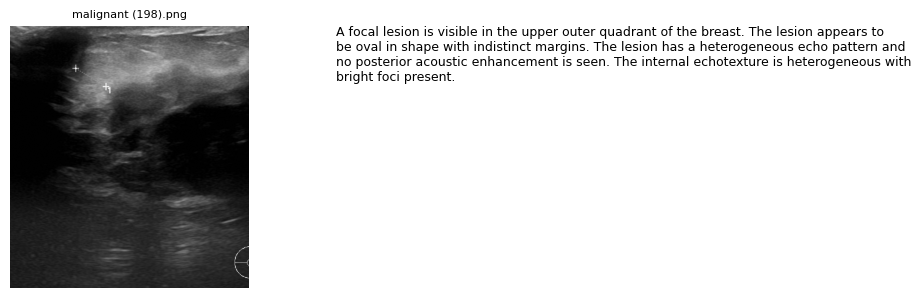

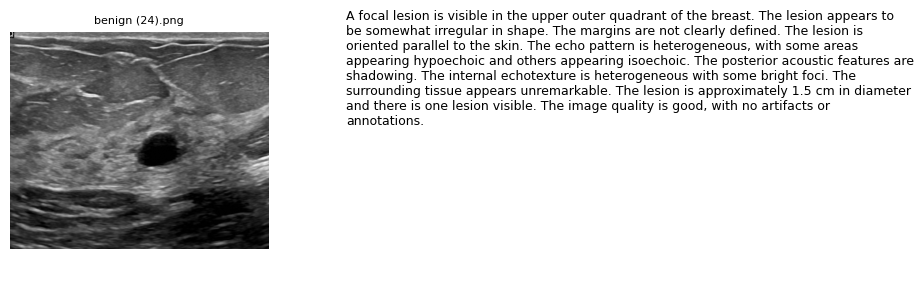

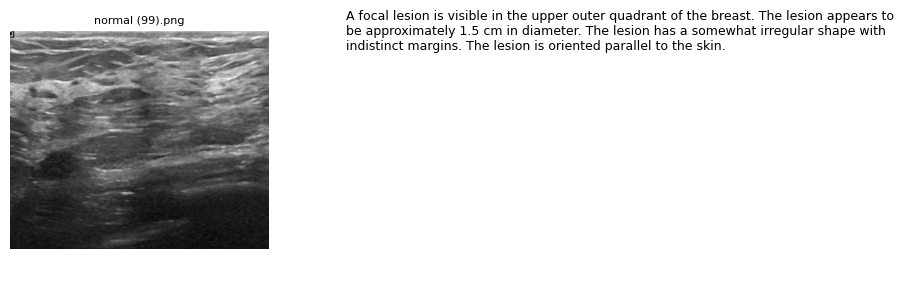

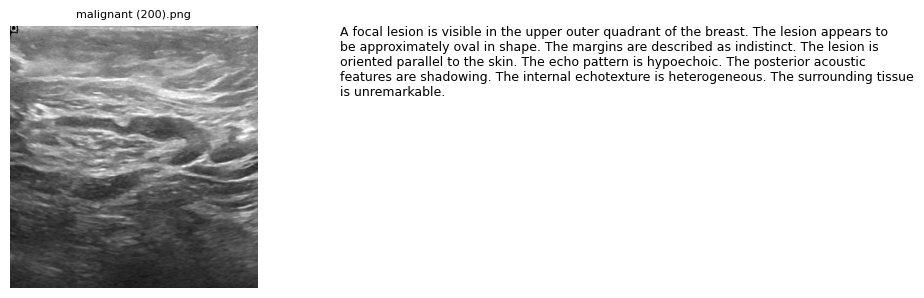

audit file: /content/drive/MyDrive/medvlm_fusion/audit_busi.csv | change start= to page through the rest


In [17]:
def audit(ds, n=25, seed=0, start=0, show=5):
    caps = load_caps(ds)
    ids = sorted(caps); random.Random(seed).shuffle(ids); ids = ids[:n]
    p = WORK / f'audit_{ds}.csv'
    if not p.exists():
        pd.DataFrame({'id': ids, 'description': [(caps[i]['parsed'] or {}).get('description', caps[i]['raw'][:300]) for i in ids],
                      'faithful': '', 'notes': ''}).to_csv(p, index=False)
    path = DF[ds].set_index('id')['path']
    for i in ids[start:start + show]:
        fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [1, 2]})
        ax[0].imshow(Image.open(path[i]).convert('L'), cmap='gray'); ax[0].axis('off')
        d = (caps[i]['parsed'] or {}).get('description', caps[i]['raw'][:400])
        ax[1].text(0, 1, textwrap.fill(d, 90), va='top', fontsize=9); ax[1].axis('off')
        ax[0].set_title(i.split('|')[-1], fontsize=8); plt.show()
    print('audit file:', p, '| change start= to page through the rest')
audit('busi', start=0)

In [ ]:
audit('covid', start=0)

## Notes for the writeup
- Training subsets are independent class-balanced draws (not 5-fold CV), COVID test set is capped (`TEST_CAP`). State both.
- The local branch is DKA-inspired and sits on the head, not inside the transformer blocks.
- Report MedGemma model ID, commit hash, dtype, prompt and greedy decoding (saved in `vlm_meta.json`), plus the leakage-check numbers and the manual audit.
- MedGemma may have seen public datasets like COVID or BUSI in training; list it under limitations.
- SEN is macro-averaged recall here; say so if the DKA paper's definition differs.
- Tune `LR_NEW` / `LR_HEAD` on validation folds of the training subset, never on the test set.